# Evaluación comparativa de tres modelos: baseline, clDice v1 y clDice v2

Comparación de los tres experimentos de segmentación (baseline Dice + CE, clDice v1 y clDice v2) sobre los mismos 40 casos de validación del fold 0.

No se repite la inferencia: se reutilizan las predicciones de validación guardadas por nnU-Net (`--npz`) y se calculan Dice, clDice (versión dura) y número de componentes conexas para los tres modelos.


In [1]:
from google.colab import drive
drive.mount("/content/drive")


Mounted at /content/drive


In [2]:
import os
from pathlib import Path

BASE = Path("/content/drive/MyDrive/TFM_nnUNet")

NNUNET_RAW = BASE / "nnUNet_raw"
NNUNET_PREPROCESSED = BASE / "nnUNet_preprocessed"
NNUNET_RESULTS = BASE / "nnUNet_results"

os.environ["nnUNet_raw"] = str(NNUNET_RAW)
os.environ["nnUNet_preprocessed"] = str(NNUNET_PREPROCESSED)
os.environ["nnUNet_results"] = str(NNUNET_RESULTS)


In [3]:
!pip install -q SimpleITK


   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 52.8/52.8 MB 52.5 MB/s eta 0:00:00


In [4]:
import numpy as np
import pandas as pd
import SimpleITK as sitk
from scipy import ndimage, stats
from skimage.morphology import skeletonize
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import json

pd.set_option("display.max_columns", None)


## 1. Localizar las carpetas de validación de los tres experimentos

In [5]:
DATASET_NAME   = "Dataset501_ImageCAS"
PLANS_NAME     = "nnUNetPlans"
CONFIGURATION  = "3d_fullres"
FOLD           = 0

TRAINERS = {
    "Dice+CE (baseline)":               "nnUNetTrainer_100epochs",
    "Dice+CE+soft-clDice v1":           "nnUNetTrainerSoftClDice100epochs",
    "Dice+CE+soft-clDice v2":           "nnUNetTrainerSoftClDiceV2_100epochs",
}

def validation_folder(trainer_name):
    return (
        NNUNET_RESULTS
        / DATASET_NAME
        / f"{trainer_name}__{PLANS_NAME}__{CONFIGURATION}"
        / f"fold_{FOLD}"
        / "validation"
    )

VAL_FOLDERS = {label: validation_folder(tr) for label, tr in TRAINERS.items()}
LABELS_DIR = NNUNET_RAW / DATASET_NAME / "labelsTr"

for label, folder in VAL_FOLDERS.items():
    print(f"{label:35s} -> existe: {folder.exists():5}  ({folder})")
print("Labels folder existe:", LABELS_DIR.exists())


Dice+CE (baseline)                  -> existe:     1  (/content/drive/MyDrive/TFM_nnUNet/nnUNet_results/Dataset501_ImageCAS/nnUNetTrainer_100epochs__nnUNetPlans__3d_fullres/fold_0/validation)
Dice+CE+soft-clDice v1              -> existe:     1  (/content/drive/MyDrive/TFM_nnUNet/nnUNet_results/Dataset501_ImageCAS/nnUNetTrainerSoftClDice100epochs__nnUNetPlans__3d_fullres/fold_0/validation)
Dice+CE+soft-clDice v2              -> existe:     1  (/content/drive/MyDrive/TFM_nnUNet/nnUNet_results/Dataset501_ImageCAS/nnUNetTrainerSoftClDiceV2_100epochs__nnUNetPlans__3d_fullres/fold_0/validation)
Labels folder existe: True


In [6]:
def list_case_ids(validation_folder):
    files = sorted(validation_folder.glob("*.nii.gz"))
    return sorted(f.stem.replace(".nii", "") for f in files)

cases_by_model = {label: list_case_ids(folder) for label, folder in VAL_FOLDERS.items()}

for label, cases in cases_by_model.items():
    print(f"{label:35s} -> {len(cases)} casos")

all_case_sets = [set(c) for c in cases_by_model.values()]
assert all(s == all_case_sets[0] for s in all_case_sets), "Los experimentos no comparten el mismo set de validacion!"
common_cases = sorted(all_case_sets[0])
print("\nComparacion pareada sobre", len(common_cases), "casos comunes a los 3 modelos.")


Dice+CE (baseline)                  -> 40 casos
Dice+CE+soft-clDice v1              -> 40 casos
Dice+CE+soft-clDice v2              -> 40 casos

Comparacion pareada sobre 40 casos comunes a los 3 modelos.


## 2. Funciones de métricas


In [7]:
def dice_score(pred, gt, eps=1e-6):
    pred = pred.astype(bool)
    gt = gt.astype(bool)
    inter = np.logical_and(pred, gt).sum()
    return (2.0 * inter + eps) / (pred.sum() + gt.sum() + eps)


def cldice_score(pred, gt, eps=1e-6):
    pred = pred.astype(bool)
    gt = gt.astype(bool)

    skel_pred = skeletonize(pred)
    skel_gt = skeletonize(gt)

    tprec = (np.logical_and(skel_pred, gt).sum() + eps) / (skel_pred.sum() + eps)
    tsens = (np.logical_and(skel_gt, pred).sum() + eps) / (skel_gt.sum() + eps)

    cldice = (2.0 * tprec * tsens) / (tprec + tsens + eps)
    return cldice, tprec, tsens


def connected_components(mask):
    structure = ndimage.generate_binary_structure(mask.ndim, 3)
    labeled, n = ndimage.label(mask.astype(bool), structure=structure)
    return n


def largest_component_coverage(pred, gt, connectivity=3):
    # Fracción del GT cubierta por la componente conexa más grande de la predicción
    # (continuidad del vaso reconstruido de una pieza)
    pred = pred.astype(bool)
    gt = gt.astype(bool)

    structure = ndimage.generate_binary_structure(pred.ndim, connectivity)
    labeled, n = ndimage.label(pred, structure=structure)

    if n == 0:
        return 0.0

    sizes = ndimage.sum(pred, labeled, range(1, n + 1))
    largest_label = np.argmax(sizes) + 1
    largest_component = (labeled == largest_label)

    coverage = np.logical_and(largest_component, gt).sum() / (gt.sum() + 1e-6)
    return coverage


def significant_breaks(pred, connectivity=3, min_size=20):
    # Número de componentes conexas de tamaño relevante (se descartan fragmentos de pocos vóxeles)
    pred = pred.astype(bool)
    structure = ndimage.generate_binary_structure(pred.ndim, connectivity)
    labeled, n = ndimage.label(pred, structure=structure)

    if n == 0:
        return 0

    sizes = ndimage.sum(pred, labeled, range(1, n + 1))
    return int((sizes >= min_size).sum())


def load_binary_mask(path):
    img = sitk.ReadImage(str(path))
    arr = sitk.GetArrayFromImage(img)
    return (arr > 0).astype(np.uint8)


def evaluate_case(case_id, validation_folder, labels_dir):
    pred_path = validation_folder / f"{case_id}.nii.gz"
    gt_path = labels_dir / f"{case_id}.nii.gz"

    pred = load_binary_mask(pred_path)
    gt = load_binary_mask(gt_path)

    assert pred.shape == gt.shape, f"Shape mismatch en {case_id}: {pred.shape} vs {gt.shape}"

    dice = dice_score(pred, gt)
    cldice, tprec, tsens = cldice_score(pred, gt)
    n_components_pred = connected_components(pred)
    n_components_gt = connected_components(gt)
    coverage_principal = largest_component_coverage(pred, gt)
    n_breaks_significativos = significant_breaks(pred, min_size=20)

    return {
        "case_id": case_id,
        "dice": dice,
        "cldice": cldice,
        "topo_precision": tprec,
        "topo_sensitivity": tsens,
        "n_components_pred": n_components_pred,
        "n_components_gt": n_components_gt,
        "cobertura_componente_principal": coverage_principal,
        "n_componentes_significativas": n_breaks_significativos,
    }


## 3. Evaluación de los tres modelos sobre los 40 casos comunes

El cálculo requiere más tiempo que la comparación de dos modelos de la evaluación original (3 modelos × 40 casos).


In [ ]:
dfs = {}

for label, folder in VAL_FOLDERS.items():
    results = []
    for case_id in tqdm(common_cases, desc=f"Evaluando: {label}"):
        results.append(evaluate_case(case_id, folder, LABELS_DIR))
    df = pd.DataFrame(results)
    df["model"] = label
    dfs[label] = df

dfs["Dice+CE (baseline)"].head()


Evaluando: Dice+CE (baseline):   0%|          | 0/40 [00:00<?, ?it/s]

Evaluando: Dice+CE+soft-clDice v1:   0%|          | 0/40 [00:00<?, ?it/s]

Evaluando: Dice+CE+soft-clDice v2:   0%|          | 0/40 [00:00<?, ?it/s]

,case_id,dice,cldice,topo_precision,topo_sensitivity,n_components_pred,n_components_gt,cobertura_componente_principal,n_componentes_significativas,model
0,ImageCAS_0011,0.697345,0.771060,0.643670,0.961315,17,3,0.451368,14,Dice+CE (baseline)
1,ImageCAS_0017,0.711042,0.750254,0.679880,0.836879,17,2,0.339008,13,Dice+CE (baseline)
2,ImageCAS_0018,0.709800,0.781704,0.667696,0.942664,15,2,0.525682,14,Dice+CE (baseline)
3,ImageCAS_0021,0.609545,0.714436,0.578133,0.934839,34,2,0.517066,29,Dice+CE (baseline)
4,ImageCAS_0028,0.785743,0.821244,0.907445,0.750000,5,2,0.390265,4,Dice+CE (baseline)


## 4. Tabla resumen de los tres modelos

In [ ]:
summary_rows = {}
for label, df in dfs.items():
    summary_rows[label] = {
        "Dice":                    df["dice"].mean(),
        "Dice (std)":              df["dice"].std(),
        "clDice":                  df["cldice"].mean(),
        "clDice (std)":            df["cldice"].std(),
        "Topo Precision":          df["topo_precision"].mean(),
        "Topo Sensitivity":        df["topo_sensitivity"].mean(),
        "Nº comp. medio (pred)":   df["n_components_pred"].mean(),
        "% casos con 1 sola comp.": (df["n_components_pred"] == 1).mean() * 100,
        "Cobertura comp. principal (media)": df["cobertura_componente_principal"].mean(),
        "Cobertura comp. principal (mediana)": df["cobertura_componente_principal"].median(),
        "Nº comp. significativas (media, >=20vox)": df["n_componentes_significativas"].mean(),
    }

summary_table = pd.DataFrame(summary_rows).T
summary_table.round(4)


,Dice,Dice (std),clDice,clDice (std),Topo Precision,Topo Sensitivity,Nº comp. medio (pred),% casos con 1 sola comp.,Cobertura comp. principal (media),Cobertura comp. principal (mediana),"Nº comp. significativas (media, >=20vox)"
Dice+CE (baseline),0.7459,0.0656,0.8069,0.0703,0.7413,0.8960,17.150,0.0,0.4810,0.4588,14.80
Dice+CE+soft-clDice v1,0.7549,0.0656,0.8221,0.0714,0.7639,0.9004,14.725,0.0,0.4829,0.4670,13.00
Dice+CE+soft-clDice v2,0.7482,0.0628,0.8094,0.0674,0.7374,0.9069,16.100,0.0,0.4798,0.4519,14.35


## 4b. Métrica de continuidad: cobertura de la componente principal

Fracción del árbol coronario de referencia (GT) contenida en la componente conexa más grande de la predicción. Un valor de 1.0 indica que toda la predicción correcta forma un único árbol continuo; valores bajos indican que el vaso predicho se fragmenta en varios trozos y ninguno cubre por sí solo el árbol completo.

Se complementa con el número de componentes significativas (≥ 20 vóxeles), que descarta los fragmentos minúsculos y contabiliza únicamente las roturas de tamaño relevante.


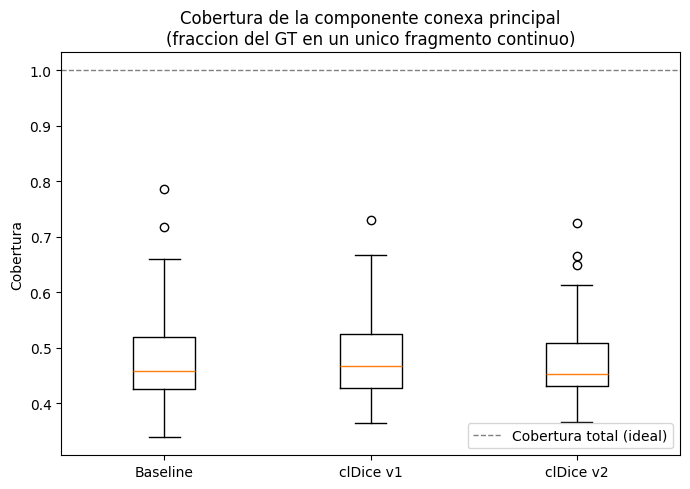

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))

data_coverage = [dfs[l]["cobertura_componente_principal"] for l in
                 ["Dice+CE (baseline)", "Dice+CE+soft-clDice v1", "Dice+CE+soft-clDice v2"]]

ax.boxplot(data_coverage, tick_labels=["Baseline", "clDice v1", "clDice v2"])
ax.axhline(1.0, color="gray", linestyle="--", linewidth=1, label="Cobertura total (ideal)")
ax.set_title("Cobertura de la componente conexa principal\n(fraccion del GT en un unico fragmento continuo)")
ax.set_ylabel("Cobertura")
ax.legend()
plt.tight_layout()
plt.savefig(BASE / "cobertura_componente_principal.png", dpi=150)
plt.show()


## 5. Tests estadísticos pareados

Se plantean tres comparaciones:
- **baseline vs v1:** efecto de clDice v1 respecto a Dice + CE.
- **baseline vs v2:** efecto de clDice v2 respecto a Dice + CE.
- **v1 vs v2:** efecto de los cambios metodológicos de v2 (clDice solo en resolución completa y warm-up) respecto a v1.


In [ ]:
def merge_two(label_a, label_b):
    return dfs[label_a].merge(dfs[label_b], on="case_id", suffixes=(f"__{label_a}", f"__{label_b}"))


def paired_tests(df_merged, col_a, col_b, label):
    a = df_merged[col_a].values
    b = df_merged[col_b].values
    diff = b - a

    w_stat, w_p = stats.wilcoxon(a, b)
    t_stat, t_p = stats.ttest_rel(a, b)

    print(f"--- {label} ---")
    print(f"Media diferencia (segundo - primero): {diff.mean():+.4f}")
    print(f"Wilcoxon signed-rank: statistic={w_stat:.3f}, p-value={w_p:.4f}")
    print(f"t-test pareado:       statistic={t_stat:.3f}, p-value={t_p:.4f}")
    print()


pairs = [
    ("Dice+CE (baseline)", "Dice+CE+soft-clDice v1"),
    ("Dice+CE (baseline)", "Dice+CE+soft-clDice v2"),
    ("Dice+CE+soft-clDice v1", "Dice+CE+soft-clDice v2"),
]

for label_a, label_b in pairs:
    merged = merge_two(label_a, label_b)
    print(f"\n========== {label_a}  vs  {label_b} ==========\n")
    paired_tests(merged, f"dice__{label_a}", f"dice__{label_b}", "Dice volumetrico")
    paired_tests(merged, f"cldice__{label_a}", f"cldice__{label_b}", "clDice")
    paired_tests(merged, f"cobertura_componente_principal__{label_a}",
                 f"cobertura_componente_principal__{label_b}",
                 "Cobertura componente principal (continuidad)")



========== Dice+CE (baseline)  vs  Dice+CE+soft-clDice v1 ==========

--- Dice volumetrico ---
Media diferencia (segundo - primero): +0.0090
Wilcoxon signed-rank: statistic=81.000, p-value=0.0000
t-test pareado:       statistic=-4.732, p-value=0.0000

--- clDice ---
Media diferencia (segundo - primero): +0.0152
Wilcoxon signed-rank: statistic=58.000, p-value=0.0000
t-test pareado:       statistic=-5.934, p-value=0.0000

--- Cobertura componente principal (continuidad) ---
Media diferencia (segundo - primero): +0.0019
Wilcoxon signed-rank: statistic=54.000, p-value=0.0000
t-test pareado:       statistic=-0.191, p-value=0.8491


========== Dice+CE (baseline)  vs  Dice+CE+soft-clDice v2 ==========

--- Dice volumetrico ---
Media diferencia (segundo - primero): +0.0023
Wilcoxon signed-rank: statistic=342.000, p-value=0.3682
t-test pareado:       statistic=-1.123, p-value=0.2682

--- clDice ---
Media diferencia (segundo - primero): +0.0025
Wilcoxon signed-rank: statistic=335.000, p-value=0

## 6. Visualización comparativa (los 3 modelos)

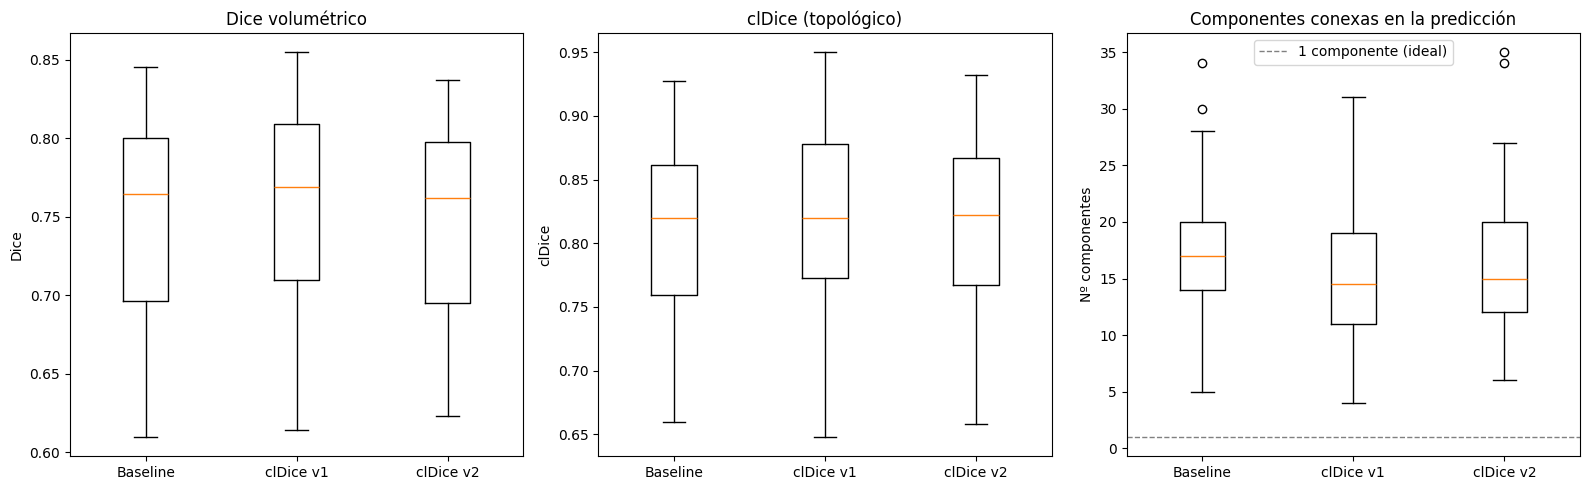

In [ ]:
labels_order = ["Dice+CE (baseline)", "Dice+CE+soft-clDice v1", "Dice+CE+soft-clDice v2"]
short_labels = ["Baseline", "clDice v1", "clDice v2"]

fig, axes = plt.subplots(1, 3, figsize=(16, 5))

data_dice = [dfs[l]["dice"] for l in labels_order]
data_cldice = [dfs[l]["cldice"] for l in labels_order]
data_ncomp = [dfs[l]["n_components_pred"] for l in labels_order]

axes[0].boxplot(data_dice, tick_labels=short_labels)
axes[0].set_title("Dice volumétrico")
axes[0].set_ylabel("Dice")

axes[1].boxplot(data_cldice, tick_labels=short_labels)
axes[1].set_title("clDice (topológico)")
axes[1].set_ylabel("clDice")

axes[2].boxplot(data_ncomp, tick_labels=short_labels)
axes[2].axhline(1, color="gray", linestyle="--", linewidth=1, label="1 componente (ideal)")
axes[2].set_title("Componentes conexas en la predicción")
axes[2].set_ylabel("Nº componentes")
axes[2].legend()

plt.tight_layout()
plt.savefig(BASE / "comparacion_3_modelos.png", dpi=150)
plt.show()


## 7. Guardar resultados

In [ ]:
output_dir = BASE / "evaluacion_comparativa"
output_dir.mkdir(parents=True, exist_ok=True)

for label, df in dfs.items():
    safe_name = label.lower().replace(" ", "_").replace("+", "").replace("(", "").replace(")", "")
    df.to_csv(output_dir / f"resultados_{safe_name}.csv", index=False)

summary_table.to_csv(output_dir / "tabla_resumen_3_modelos.csv")

print("Guardado en:", output_dir)
for f in sorted(output_dir.glob("*3_modelos*")) + sorted(output_dir.glob("resultados_*")):
    print(" -", f.name)


Guardado en: /content/drive/MyDrive/TFM_nnUNet/evaluacion_comparativa
 - tabla_resumen_3_modelos.csv
 - resultados_baseline.csv
 - resultados_dicece_baseline.csv
 - resultados_dicecesoft-cldice_v1.csv
 - resultados_dicecesoft-cldice_v2.csv
 - resultados_pareados.csv
 - resultados_soft_cldice.csv
